<a href="https://colab.research.google.com/github/Ariqq16/ML_2026/blob/main/JS09/JS09_TugasLab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install annoy faiss-cpu hnswlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 14.8 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 48.9 MB/s  0:00:00
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520034 sha256=8f91ff014d312805eaa6e3524bdd274e4248ab5e2d1776ffdf758b6296b9f711
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679801 sha256=47545cad50064756c9c8dcdea6005ebb73fbc4da9b0124add6567f722a20c33b
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705e18065db4657e61fc8da54f5

In [2]:
import numpy as np
import pandas as pd
import time

from annoy import AnnoyIndex
import faiss
import hnswlib

import matplotlib.pyplot as plt

In [3]:
def buat_dataset(jumlah_data, dimensi, metric):

    np.random.seed(42)

    data = np.random.random(
        (jumlah_data, dimensi)
    ).astype('float32')

    query = np.random.random(
        (100, dimensi)
    ).astype('float32')

    if metric == 'cosine':
        data = data / np.linalg.norm(
            data, axis=1, keepdims=True
        )

        query = query / np.linalg.norm(
            query, axis=1, keepdims=True
        )

    return data, query

In [4]:
def cari_ground_truth(data, query, metric):

    dimensi = data.shape[1]

    if metric == 'euclidean':
        index = faiss.IndexFlatL2(dimensi)
    else:
        index = faiss.IndexFlatIP(dimensi)

    index.add(data)

    distances, indices = index.search(query, 10)

    return indices

In [5]:
def uji_annoy(data, query, metric, ground_truth):

    jumlah_data, dimensi = data.shape

    metric_annoy = (
        'euclidean' if metric == 'euclidean'
        else 'angular'
    )

    index = AnnoyIndex(dimensi, metric_annoy)

    # Mengukur waktu pembangunan index
    start = time.time()

    for i, vector in enumerate(data):
        index.add_item(i, vector)

    index.build(10)

    build_time = time.time() - start

    # Mengukur waktu pencarian
    hasil = []

    start = time.time()

    for q in query:
        hasil.append(
            index.get_nns_by_vector(q, 10)
        )

    query_time = time.time() - start

    hasil = np.array(hasil)

    # Menghitung Recall@10
    recall = np.mean([
        len(set(hasil[i]) & set(ground_truth[i])) / 10
        for i in range(len(query))
    ])

    return build_time, query_time / len(query), recall

In [6]:
def uji_faiss(data, query, metric, ground_truth):

    jumlah_data, dimensi = data.shape

    if metric == 'euclidean':
        quantizer = faiss.IndexFlatL2(dimensi)
        index = faiss.IndexIVFFlat(
            quantizer,
            dimensi,
            min(100, max(4, int(np.sqrt(jumlah_data)))),
            faiss.METRIC_L2
        )
    else:
        quantizer = faiss.IndexFlatIP(dimensi)
        index = faiss.IndexIVFFlat(
            quantizer,
            dimensi,
            min(100, max(4, int(np.sqrt(jumlah_data)))),
            faiss.METRIC_INNER_PRODUCT
        )

    # Mengukur waktu pembangunan index
    start = time.time()

    index.train(data)
    index.add(data)

    index.nprobe = min(10, index.nlist)

    build_time = time.time() - start

    # Mengukur waktu pencarian
    start = time.time()

    distances, hasil = index.search(query, 10)

    query_time = time.time() - start

    # Menghitung Recall@10
    recall = np.mean([
        len(set(hasil[i]) & set(ground_truth[i])) / 10
        for i in range(len(query))
    ])

    return build_time, query_time / len(query), recall

In [7]:
def uji_hnsw(data, query, metric, ground_truth):

    jumlah_data, dimensi = data.shape

    space = (
        'l2' if metric == 'euclidean'
        else 'cosine'
    )

    index = hnswlib.Index(
        space=space,
        dim=dimensi
    )

    # Mengukur waktu pembangunan index
    start = time.time()

    index.init_index(
        max_elements=jumlah_data,
        ef_construction=100,
        M=16
    )

    index.add_items(data)

    index.set_ef(50)

    build_time = time.time() - start

    # Mengukur waktu pencarian
    start = time.time()

    hasil, distances = index.knn_query(
        query,
        k=10
    )

    query_time = time.time() - start

    # Menghitung Recall@10
    recall = np.mean([
        len(set(hasil[i]) & set(ground_truth[i])) / 10
        for i in range(len(query))
    ])

    return build_time, query_time / len(query), recall

In [8]:
konfigurasi = [
    (1000, 2, 'euclidean'),
    (1000, 2, 'cosine'),
    (1000000, 5, 'euclidean'),
    (1000000, 5, 'cosine')
]

hasil_eksperimen = []

for jumlah_data, dimensi, metric in konfigurasi:

    print("\n" + "=" * 55)
    print(f"DATA: {jumlah_data} | DIMENSI: {dimensi} | METRIC: {metric}")
    print("=" * 55)

    # Membuat dataset
    data, query = buat_dataset(
        jumlah_data, dimensi, metric
    )

    # Ground truth
    ground_truth = cari_ground_truth(
        data, query, metric
    )

    # ANNOY
    print("Menjalankan ANNOY...")
    build, query_time, recall = uji_annoy(
        data, query, metric, ground_truth
    )

    hasil_eksperimen.append({
        'Data/Dimensi': f'{jumlah_data}/{dimensi}D',
        'Metric': metric,
        'Algoritma': 'ANNOY',
        'Build Time (s)': build,
        'Query Time (ms)': query_time * 1000,
        'Recall@10': recall
    })

    # FAISS
    print("Menjalankan FAISS...")
    build, query_time, recall = uji_faiss(
        data, query, metric, ground_truth
    )

    hasil_eksperimen.append({
        'Data/Dimensi': f'{jumlah_data}/{dimensi}D',
        'Metric': metric,
        'Algoritma': 'FAISS',
        'Build Time (s)': build,
        'Query Time (ms)': query_time * 1000,
        'Recall@10': recall
    })

    # HNSW
    print("Menjalankan HNSW...")
    build, query_time, recall = uji_hnsw(
        data, query, metric, ground_truth
    )

    hasil_eksperimen.append({
        'Data/Dimensi': f'{jumlah_data}/{dimensi}D',
        'Metric': metric,
        'Algoritma': 'HNSW',
        'Build Time (s)': build,
        'Query Time (ms)': query_time * 1000,
        'Recall@10': recall
    })

    print("Eksperimen selesai!")


DATA: 1000 | DIMENSI: 2 | METRIC: euclidean
Menjalankan ANNOY...
Menjalankan FAISS...
Menjalankan HNSW...
Eksperimen selesai!

DATA: 1000 | DIMENSI: 2 | METRIC: cosine
Menjalankan ANNOY...
Menjalankan FAISS...
Menjalankan HNSW...
Eksperimen selesai!

DATA: 1000000 | DIMENSI: 5 | METRIC: euclidean
Menjalankan ANNOY...
Menjalankan FAISS...
Menjalankan HNSW...
Eksperimen selesai!

DATA: 1000000 | DIMENSI: 5 | METRIC: cosine
Menjalankan ANNOY...
Menjalankan FAISS...
Menjalankan HNSW...
Eksperimen selesai!


In [9]:
hasil_df = pd.DataFrame(hasil_eksperimen)

print("TABEL HASIL PERBANDINGAN ANNOY, FAISS, DAN HNSW")

display(
    hasil_df.round(4)
)

TABEL HASIL PERBANDINGAN ANNOY, FAISS, DAN HNSW


,Data/Dimensi,Metric,Algoritma,Build Time (s),Query Time (ms),Recall@10
0,1000/2D,euclidean,ANNOY,0.0416,0.0367,0.994
1,1000/2D,euclidean,FAISS,0.1491,0.0245,1.000
2,1000/2D,euclidean,HNSW,0.0562,0.0206,1.000
3,1000/2D,cosine,ANNOY,0.0740,0.0331,0.993
4,1000/2D,cosine,FAISS,0.0640,0.0323,1.000
5,1000/2D,cosine,HNSW,0.0447,0.0175,0.999
6,1000000/5D,euclidean,ANNOY,21.1793,0.0528,0.949
7,1000000/5D,euclidean,FAISS,0.2208,0.6845,1.000
8,1000000/5D,euclidean,HNSW,88.3614,0.0394,1.000
9,1000000/5D,cosine,ANNOY,28.0223,0.0589,0.980


In [10]:
tabel_recall = hasil_df.pivot_table(
    index=['Data/Dimensi', 'Metric'],
    columns='Algoritma',
    values='Recall@10'
)

display(tabel_recall.round(4))

Algoritma               ANNOY  FAISS   HNSW
Data/Dimensi Metric                        
1000/2D      cosine     0.993    1.0  0.999
             euclidean  0.994    1.0  1.000
1000000/5D   cosine     0.980    1.0  1.000
             euclidean  0.949    1.0  1.000

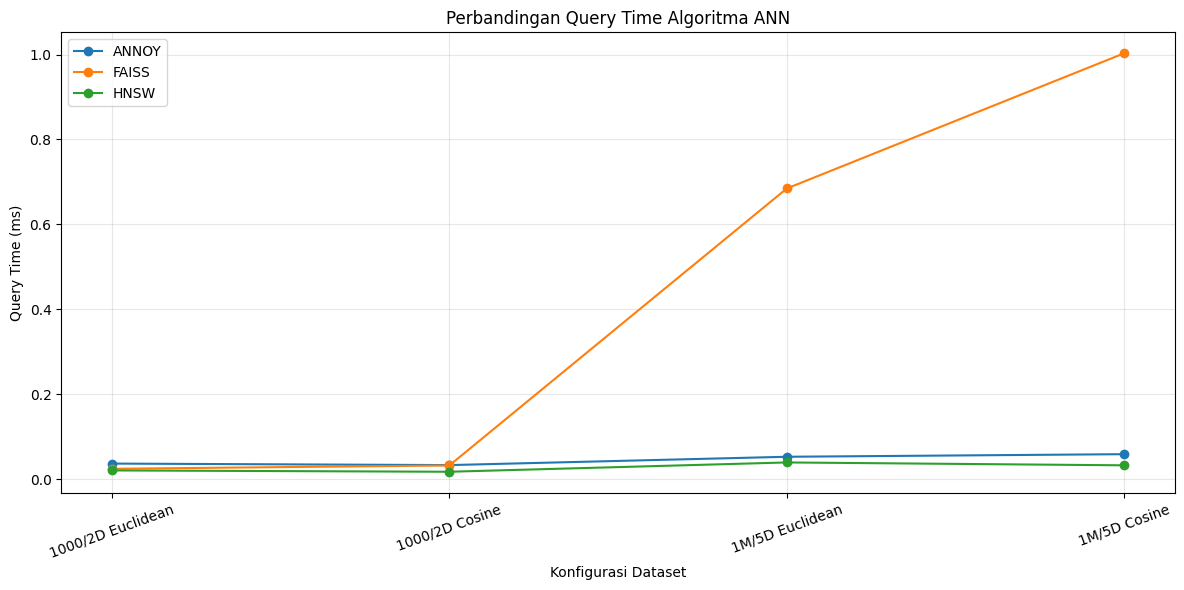

In [11]:
plt.figure(figsize=(12, 6))

for algoritma in ['ANNOY', 'FAISS', 'HNSW']:

    subset = hasil_df[
        hasil_df['Algoritma'] == algoritma
    ]

    plt.plot(
        range(len(subset)),
        subset['Query Time (ms)'],
        marker='o',
        label=algoritma
    )

plt.xticks(
    range(4),
    [
        '1000/2D Euclidean',
        '1000/2D Cosine',
        '1M/5D Euclidean',
        '1M/5D Cosine'
    ],
    rotation=20
)

plt.title('Perbandingan Query Time Algoritma ANN')
plt.xlabel('Konfigurasi Dataset')
plt.ylabel('Query Time (ms)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()